# **WEEK 13-14**

Extra library installation

In [ ]:
!pip install -q xgboost lightgbm
print("Library Installed!")

Library Installed!


Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, learning_curve
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, mean_squared_error

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

sns.set_theme(style="whitegrid")
print("Libraries loaded!")

Libraries loaded!


LOAD DATASET

In [ ]:
# Using sklearn's built-in Breast Cancer dataset - real diagnostic data used to classify tumors as malignant or benign.
cancer = load_breast_cancer(as_frame=True)
df = cancer.frame
X = df.drop(columns=['target'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Dataset shape:", df.shape, "| Classes:", cancer.target_names)

Dataset shape: (569, 31) | Classes: ['malignant' 'benign']


BASELINE: SINGLE DECISION TREE

In [ ]:
# Decision Tree - a single model that splits data into branches based on feature values to reach a prediction;
# easy to understand but prone to overfitting (memorizing training data) if left unrestricted.
single_tree = DecisionTreeClassifier(random_state=42)
single_tree.fit(X_train_scaled, y_train)
tree_acc = accuracy_score(y_test, single_tree.predict(X_test_scaled))
print("Single Decision Tree Accuracy:", round(tree_acc, 3))

Single Decision Tree Accuracy: 0.912


ENSEMBLE: BAGGING

In [ ]:
# Bagging (Bootstrap Aggregating) - trains MANY copies of a model (usually decision trees) on different random
# subsets of the training data (sampled with replacement), then averages/votes their predictions. This reduces
# variance and makes the overall model more stable than any single tree.
bagging_clf = BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100, random_state=42)
bagging_clf.fit(X_train_scaled, y_train)
bagging_acc = accuracy_score(y_test, bagging_clf.predict(X_test_scaled))
print("Bagging Classifier Accuracy:", round(bagging_acc, 3))

# Random Forest - a popular, improved version of Bagging specifically for trees: besides sampling rows randomly,
# it also picks a random subset of features at each split, making the individual trees more diverse/independent.
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train_scaled, y_train)
rf_acc = accuracy_score(y_test, rf_clf.predict(X_test_scaled))
print("Random Forest Accuracy:", round(rf_acc, 3))

Bagging Classifier Accuracy: 0.939
Random Forest Accuracy: 0.956


ENSEMBLE: BOOSTING

In [ ]:
# Boosting - trains models ONE AFTER ANOTHER (sequentially), where each new model focuses specifically on
# correcting the mistakes made by the previous ones, gradually "boosting" overall performance. Unlike Bagging
# (parallel, reduces variance), Boosting mainly reduces bias by building a strong model out of many weak ones.
gb_clf = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
gb_clf.fit(X_train_scaled, y_train)
gb_acc = accuracy_score(y_test, gb_clf.predict(X_test_scaled))
print("Gradient Boosting Accuracy:", round(gb_acc, 3))

# XGBoost (Extreme Gradient Boosting) - a highly optimized, faster, and more regularized implementation of
# gradient boosting; extremely popular in ML competitions for its speed and accuracy on structured/tabular data.
xgb_clf = XGBClassifier(n_estimators=100, learning_rate=0.1, use_label_encoder=False, eval_metric='logloss', random_state=42)
xgb_clf.fit(X_train_scaled, y_train)
xgb_acc = accuracy_score(y_test, xgb_clf.predict(X_test_scaled))
print("XGBoost Accuracy:", round(xgb_acc, 3))

# LightGBM (Light Gradient Boosting Machine) - another gradient boosting implementation, designed by Microsoft to be
# even faster and more memory-efficient than XGBoost, especially on very large datasets, using a leaf-wise tree growth strategy.
lgbm_clf = LGBMClassifier(n_estimators=100, learning_rate=0.1, random_state=42, verbose=-1)
lgbm_clf.fit(X_train_scaled, y_train)
lgbm_acc = accuracy_score(y_test, lgbm_clf.predict(X_test_scaled))
print("LightGBM Accuracy:", round(lgbm_acc, 3))

Gradient Boosting Accuracy: 0.956


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [05:16:26] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Accuracy: 0.947
LightGBM Accuracy: 0.956


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Ensemble Methods - Visual Comparison

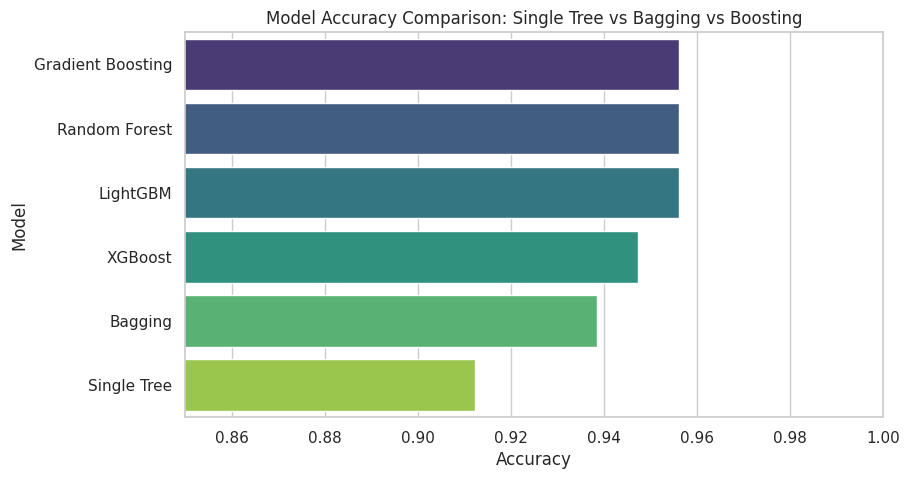

               Model  Accuracy
3  Gradient Boosting  0.956140
2      Random Forest  0.956140
5           LightGBM  0.956140
4            XGBoost  0.947368
1            Bagging  0.938596
0        Single Tree  0.912281


In [ ]:
results = pd.DataFrame({
    'Model': ['Single Tree', 'Bagging', 'Random Forest', 'Gradient Boosting', 'XGBoost', 'LightGBM'],
    'Accuracy': [tree_acc, bagging_acc, rf_acc, gb_acc, xgb_acc, lgbm_acc]
}).sort_values(by='Accuracy', ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(data=results, x='Accuracy', y='Model', hue='Model', palette='viridis', legend=False)
plt.title("Model Accuracy Comparison: Single Tree vs Bagging vs Boosting")
plt.xlim(0.85, 1.0)
plt.show()
print(results)

BIAS-VARIANCE TRADEOFF (Intuition with Polynomial Regression)

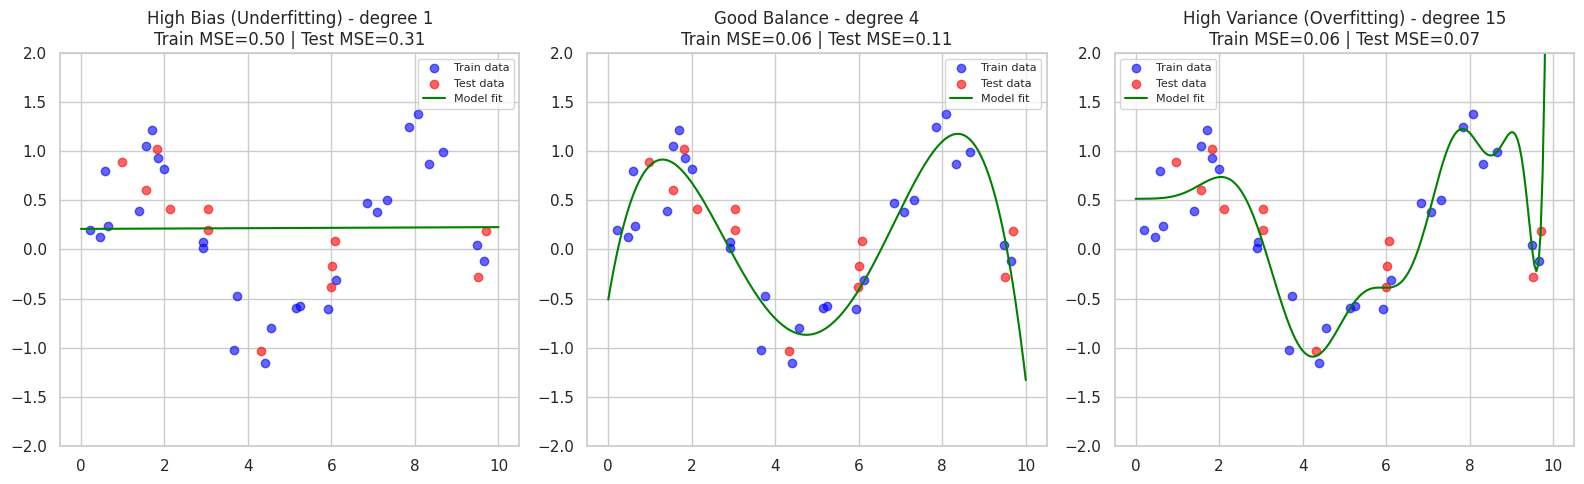

In [ ]:
# Bias-Variance Tradeoff - Bias is the error from a model being TOO SIMPLE (it misses real patterns = underfitting).
# Variance is the error from a model being TOO COMPLEX (it learns noise instead of real patterns = overfitting).
# A good model finds the balance: simple enough to generalize, complex enough to capture true patterns.

# Creating a synthetic non-linear dataset to visualize this tradeoff clearly
np.random.seed(42)
X_syn = np.sort(np.random.rand(40, 1) * 10, axis=0)
y_syn = np.sin(X_syn).ravel() + np.random.normal(0, 0.3, X_syn.shape[0])

X_syn_train, X_syn_test, y_syn_train, y_syn_test = train_test_split(X_syn, y_syn, test_size=0.3, random_state=42)

degrees = [1, 4, 15]   # low (underfit), medium (good fit), high (overfit)
titles = ['High Bias (Underfitting) - degree 1', 'Good Balance - degree 4', 'High Variance (Overfitting) - degree 15']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
X_plot = np.linspace(0, 10, 200).reshape(-1, 1)

for i, degree in enumerate(degrees):
    poly = PolynomialFeatures(degree=degree)
    X_train_poly = poly.fit_transform(X_syn_train)
    X_test_poly = poly.transform(X_syn_test)
    X_plot_poly = poly.transform(X_plot)

    lin_model = LinearRegression()
    lin_model.fit(X_train_poly, y_syn_train)

    train_err = mean_squared_error(y_syn_train, lin_model.predict(X_train_poly))
    test_err = mean_squared_error(y_syn_test, lin_model.predict(X_test_poly))

    axes[i].scatter(X_syn_train, y_syn_train, color='blue', label='Train data', alpha=0.6)
    axes[i].scatter(X_syn_test, y_syn_test, color='red', label='Test data', alpha=0.6)
    axes[i].plot(X_plot, lin_model.predict(X_plot_poly), color='green', label='Model fit')
    axes[i].set_ylim(-2, 2)
    axes[i].set_title(f"{titles[i]}\nTrain MSE={train_err:.2f} | Test MSE={test_err:.2f}")
    axes[i].legend(fontsize=8)

plt.tight_layout()
plt.show()

OVERFITTING / UNDERFITTING (Train vs Test Accuracy by Model Complexity)

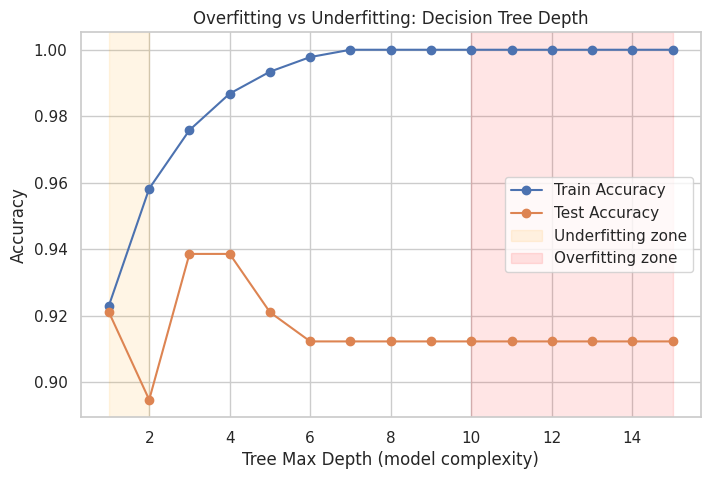

In [ ]:
# Overfitting - when a model performs very well on training data but poorly on new/test data, because it
# "memorized" training data (including noise) instead of learning general patterns.
# Underfitting - when a model performs poorly on BOTH training and test data, because it's too simple to
# capture the real patterns in the data.

max_depths = range(1, 16)
train_accuracies = []
test_accuracies = []

for depth in max_depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train_scaled, y_train)
    train_accuracies.append(accuracy_score(y_train, tree.predict(X_train_scaled)))
    test_accuracies.append(accuracy_score(y_test, tree.predict(X_test_scaled)))

plt.figure(figsize=(8, 5))
plt.plot(max_depths, train_accuracies, marker='o', label='Train Accuracy')
plt.plot(max_depths, test_accuracies, marker='o', label='Test Accuracy')
plt.axvspan(1, 2, color='orange', alpha=0.1, label='Underfitting zone')
plt.axvspan(10, 15, color='red', alpha=0.1, label='Overfitting zone')
plt.xlabel("Tree Max Depth (model complexity)")
plt.ylabel("Accuracy")
plt.title("Overfitting vs Underfitting: Decision Tree Depth")
plt.legend()
plt.show()

REGULARIZATION (L1 / L2)

L2 Regularized Logistic Regression Accuracy: 0.982
L1 Regularized Logistic Regression Accuracy: 0.991

Number of features with zero coefficient (L1): 14 out of 30


<Figure size 1000x800 with 0 Axes>

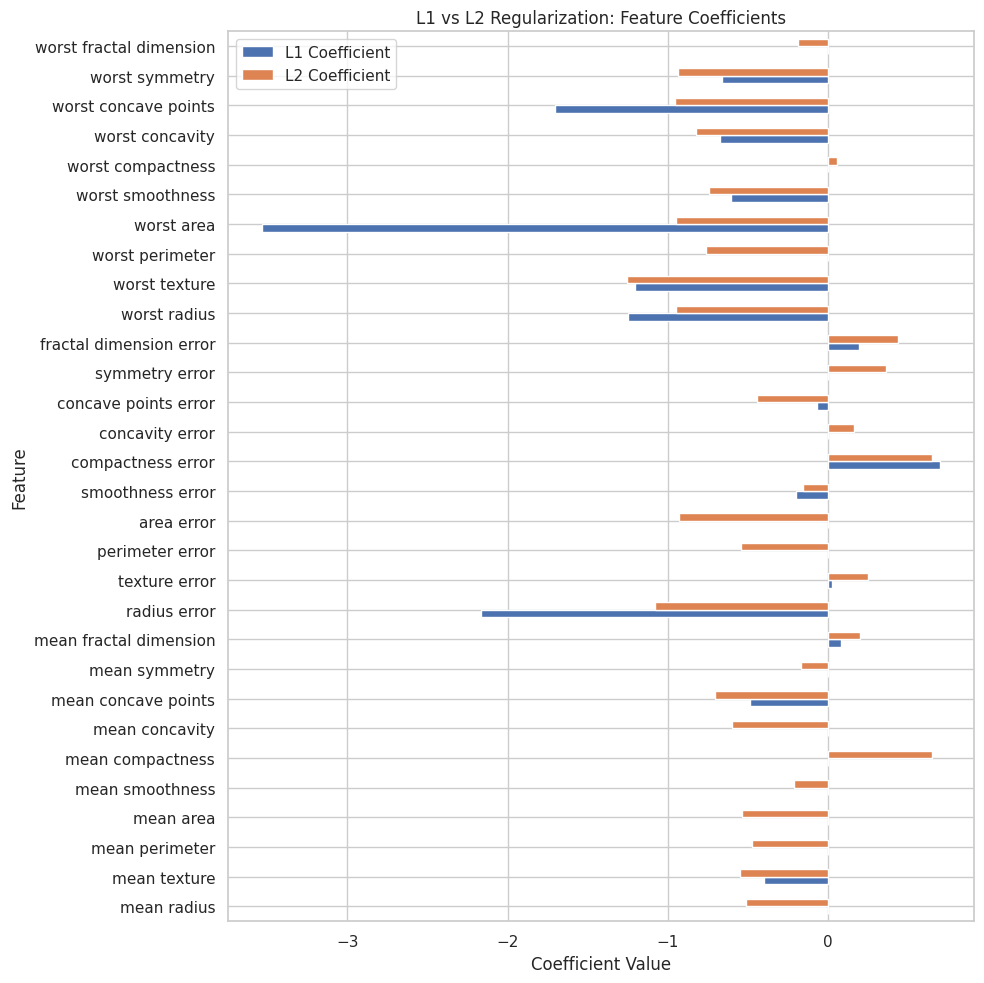

In [ ]:
# Regularization - adds a penalty to the model's loss function based on the size of its coefficients/weights,
# discouraging the model from becoming too complex and fitting noise. This directly helps reduce overfitting
# (lowers variance) at the cost of a small increase in bias.

# L2 Regularization (Ridge-style) - penalizes the SQUARE of coefficients, shrinking all weights smoothly
# towards zero but rarely making them exactly zero; keeps all features but reduces their individual impact.
log_reg_l2 = LogisticRegression(penalty='l2', C=1.0, max_iter=5000)
log_reg_l2.fit(X_train_scaled, y_train)
l2_acc = accuracy_score(y_test, log_reg_l2.predict(X_test_scaled))

# L1 Regularization (Lasso-style) - penalizes the ABSOLUTE VALUE of coefficients, which can shrink some
# weights to EXACTLY zero, effectively removing less-important features automatically (built-in feature selection).
log_reg_l1 = LogisticRegression(penalty='l1', solver='liblinear', C=1.0, max_iter=5000)
log_reg_l1.fit(X_train_scaled, y_train)
l1_acc = accuracy_score(y_test, log_reg_l1.predict(X_test_scaled))

print("L2 Regularized Logistic Regression Accuracy:", round(l2_acc, 3))
print("L1 Regularized Logistic Regression Accuracy:", round(l1_acc, 3))
print("\nNumber of features with zero coefficient (L1):", np.sum(log_reg_l1.coef_[0] == 0), "out of", len(log_reg_l1.coef_[0]))

# Visualizing how L1 shrinks some coefficients to exactly zero, while L2 shrinks all smoothly
coef_compare = pd.DataFrame({
    'Feature': X.columns,
    'L1 Coefficient': log_reg_l1.coef_[0],
    'L2 Coefficient': log_reg_l2.coef_[0]
})

plt.figure(figsize=(10, 8))
coef_compare_sorted = coef_compare.set_index('Feature')[['L1 Coefficient', 'L2 Coefficient']]
coef_compare_sorted.plot(kind='barh', figsize=(10, 10))
plt.title("L1 vs L2 Regularization: Feature Coefficients")
plt.xlabel("Coefficient Value")
plt.tight_layout()
plt.show()

Regularization - Effect of Strength (C) on Overfitting

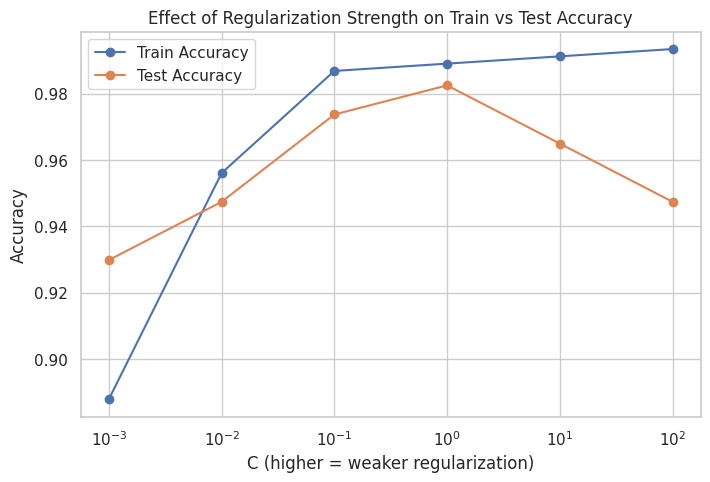

Week 13-14 demo complete, Ensemble Methods (Bagging, Boosting, XGBoost, LightGBM) + Bias-Variance Tradeoff + Overfitting/Underfitting + Regularization (L1/L2) covered!


In [ ]:

# 'C' in sklearn's LogisticRegression is the INVERSE of regularization strength: smaller C = stronger
# regularization (simpler model, more bias); larger C = weaker regularization (more complex model, more variance).
C_values = [0.001, 0.01, 0.1, 1, 10, 100]
train_scores = []
test_scores = []

for C in C_values:
    model = LogisticRegression(penalty='l2', C=C, max_iter=5000)
    model.fit(X_train_scaled, y_train)
    train_scores.append(accuracy_score(y_train, model.predict(X_train_scaled)))
    test_scores.append(accuracy_score(y_test, model.predict(X_test_scaled)))

plt.figure(figsize=(8, 5))
plt.plot(C_values, train_scores, marker='o', label='Train Accuracy')
plt.plot(C_values, test_scores, marker='o', label='Test Accuracy')
plt.xscale('log')
plt.xlabel("C (higher = weaker regularization)")
plt.ylabel("Accuracy")
plt.title("Effect of Regularization Strength on Train vs Test Accuracy")
plt.legend()
plt.show()

print("Week 13-14 demo complete, Ensemble Methods (Bagging, Boosting, XGBoost, LightGBM) + Bias-Variance Tradeoff + Overfitting/Underfitting + Regularization (L1/L2) covered!")